# Calories Burn Prediction using Encoder–Decoder Architecture

This project develops an Encoder–Decoder regression pipeline to predict Calories Burned from physiological and activity-related features.

The project includes data exploration, preprocessing, feature encoding, feature importance analysis, multiple regression decoders, and R²-based model comparison.


##  Introduction

The goal of this project is to build a machine learning pipeline for predicting the number of calories burned based on physiological and activity-related features.

The pipeline follows an Encoder–Decoder architecture:

* **Encoder:** Preprocesses the input features using One-Hot Encoding for categorical data and Standard Scaling for numerical data.
* **Decoder:** Uses different regression algorithms to predict the target variable, Calories.
* **Evaluation:** Compares the performance of the different decoders using the R² metric.

The project also includes exploratory data analysis, data cleaning, feature importance analysis, regularization, and a comparison of different regression approaches.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

3. Load Dataset

In [3]:
df = pd.read_excel("../data/calories_Dataset.xlsx")
df.head()

,User_ID,Gender,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
0,14733363,male,68.0,190.0,94.0,29.0,105.000000,40.8,231
1,14861698,female,20.0,166.0,60.0,14.0,94.000000,40.3,66
2,11179863,male,69.0,179.0,NaN,5.0,247.785992,38.7,26
3,16180408,female,34.0,179.0,71.0,13.0,100.000000,40.5,71
4,17771927,female,27.0,154.0,58.0,10.0,81.000000,39.8,35


In [4]:
df.shape

(15000, 9)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   User_ID     15000 non-null  int64  
 1   Gender      14100 non-null  object 
 2   Age         15000 non-null  float64
 3   Height      15000 non-null  float64
 4   Weight      13800 non-null  float64
 5   Duration    15000 non-null  float64
 6   Heart_Rate  14340 non-null  float64
 7   Body_Temp   15000 non-null  float64
 8   Calories    15000 non-null  int64  
dtypes: float64(6), int64(2), object(1)
memory usage: 1.0+ MB


In [6]:
df.describe()

,User_ID,Age,Height,Weight,Duration,Heart_Rate,Body_Temp,Calories
count,1.500000e+04,15000.000000,15000.000000,13800.000000,15000.000000,14340.000000,15000.000000,15000.000000
mean,1.497736e+07,44.516469,181.610177,78.042049,16.112574,99.433386,41.616467,89.539533
std,2.872851e+06,22.330970,53.854951,27.334983,9.833211,29.929374,11.645061,62.456978
min,1.000116e+07,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000,1.000000
25%,1.247419e+07,28.000000,164.000000,63.000000,8.000000,89.000000,39.600000,35.000000
50%,1.499728e+07,40.000000,175.000000,75.000000,16.000000,96.000000,40.200000,79.000000
75%,1.744928e+07,57.000000,186.000000,87.000000,23.000000,103.000000,40.600000,138.000000
max,1.999965e+07,306.168733,802.138264,438.034046,111.609442,447.635709,163.437214,314.000000


In [7]:
numerical_features = [
    'Age',
    'Height',
    'Weight',
    'Duration',
    'Heart_Rate',
    'Body_Temp'
]

## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distributions and relationships between the input features and the target variable before preprocessing and modeling.


## Histogram

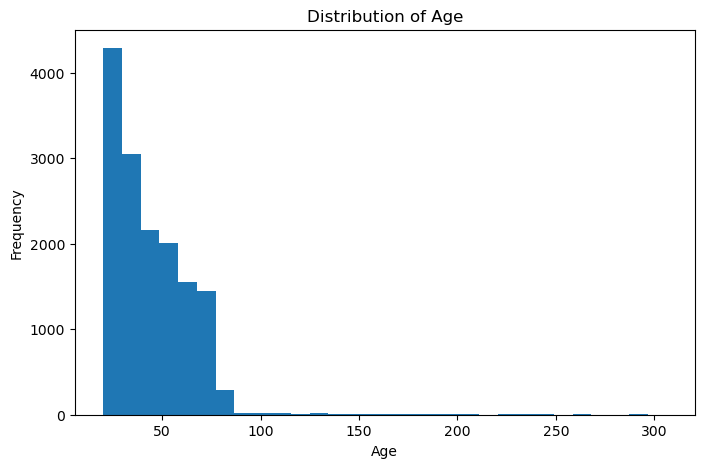

In [8]:
plt.figure(figsize=(8, 5))

plt.hist(df['Age'], bins=30)

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

The age distribution is concentrated in the lower-to-middle age range and gradually decreases as age increases. A small number of extreme values appear beyond the typical age range, indicating potential outliers that require further investigation during data cleaning

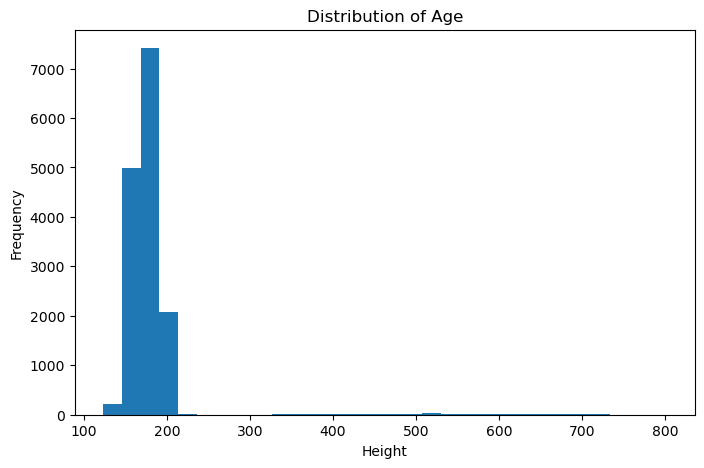

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(df['Height'], bins=30)

plt.xlabel('Height')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

Most height values are concentrated between approximately 120 and 215 cm, while a small number of extreme values extend far beyond the typical range, indicating potential outliers.

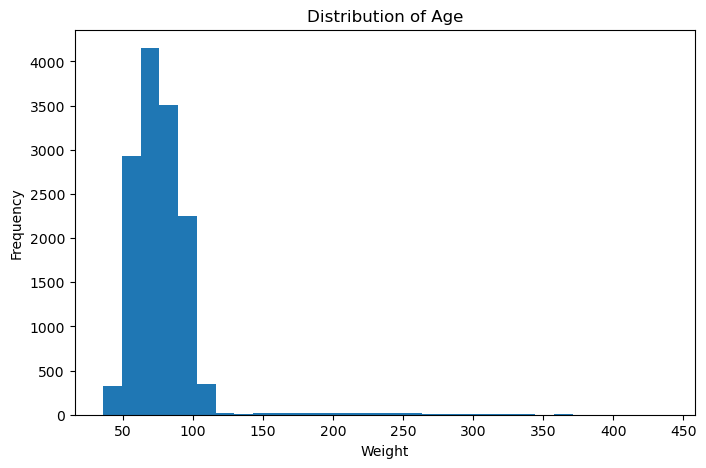

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df['Weight'], bins=30)

plt.xlabel('Weight')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

The weight distribution is concentrated around approximately 75 kg, with frequencies gradually decreasing toward higher weights. A small number of extreme values appear beyond the main distribution, indicating potential outliers.

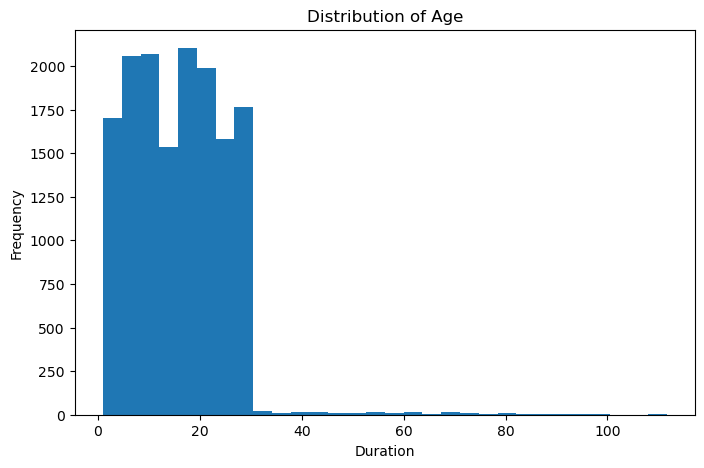

In [11]:
plt.figure(figsize=(8, 5))

plt.hist(df['Duration'], bins=30)

plt.xlabel('Duration')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

Most workout durations are concentrated between approximately 1 and 35 minutes, while a small number of observations have substantially higher durations, indicating potential extreme values.

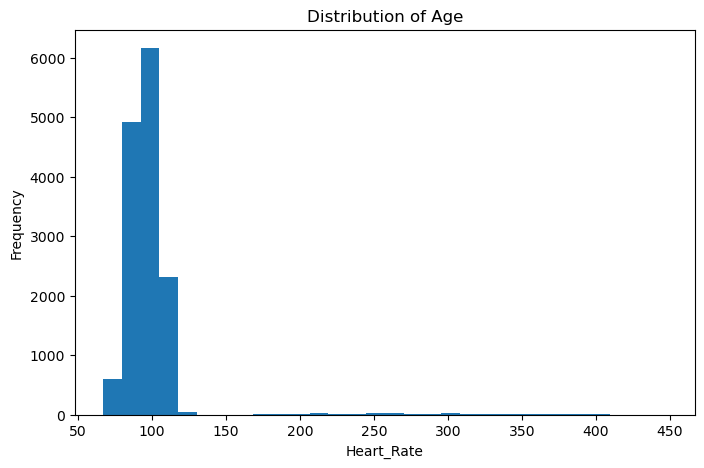

In [12]:
plt.figure(figsize=(8, 5))

plt.hist(df['Heart_Rate'], bins=30)

plt.xlabel('Heart_Rate')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

Heart rate values are mainly concentrated between approximately 70 and 115 bpm, with the highest frequency around 100 bpm. A small number of extreme high values are also present, indicating potential outliers.

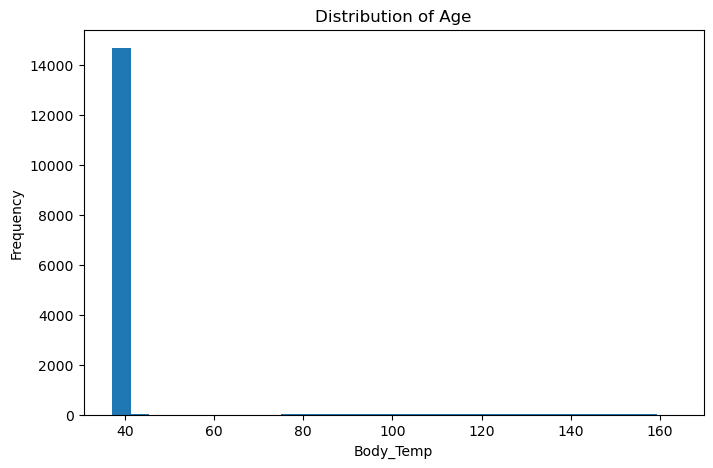

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(df['Body_Temp'], bins=30)

plt.xlabel('Body_Temp')
plt.ylabel('Frequency')
plt.title('Distribution of Age')

plt.show()

Body temperature values are highly concentrated between approximately 37°C and 42°C, while a small number of extreme values extend far beyond the main distribution, indicating potential outliers.

## Bar Chart

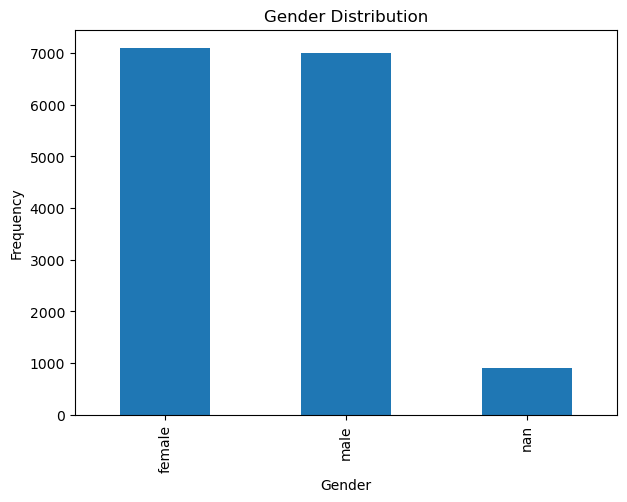

In [14]:
gender_counts = df['Gender'].value_counts(dropna=False)

plt.figure(figsize=(7, 5))

gender_counts.plot(kind='bar')

plt.xlabel('Gender')
plt.ylabel('Frequency')
plt.title('Gender Distribution')

plt.show()

The gender distribution is relatively balanced between male and female observations, while the number of missing gender values is much lower than either category.

## Box Plot 

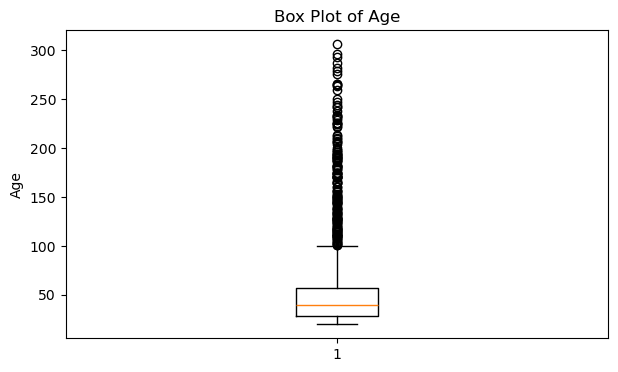

In [15]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Age'].dropna())

plt.ylabel('Age')
plt.title('Box Plot of Age')

plt.show()

The box plot shows that the median age is approximately 40 years, with the middle 50% of observations lying between 28 and 57 years. Values above approximately 100 years are identified as potential outliers using the IQR rule

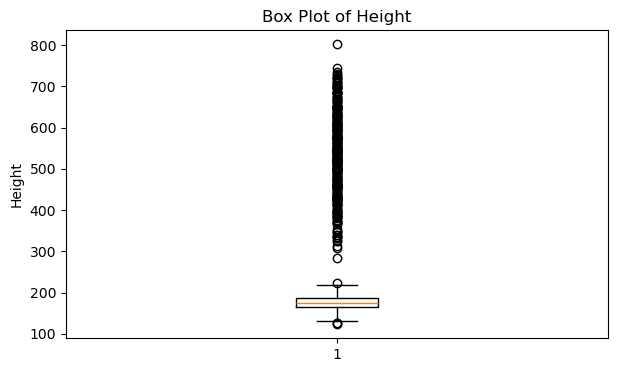

In [16]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Height'].dropna())

plt.ylabel('Height')
plt.title('Box Plot of Height')

plt.show()

In [17]:
df['Height'].describe()

count    15000.000000
mean       181.610177
std         53.854951
min        123.000000
25%        164.000000
50%        175.000000
75%        186.000000
max        802.138264
Name: Height, dtype: float64

The box plot shows that the median height is approximately 175 cm, with the middle 50% of observations lying between 164 and 186 cm. Values above approximately 219 cm are identified as potential outliers using the IQR rule.

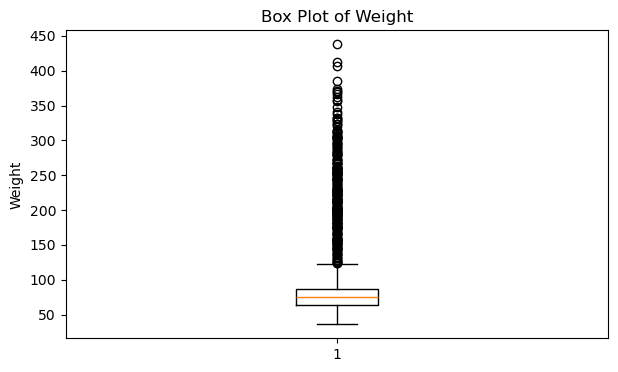

In [18]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Weight'].dropna())

plt.ylabel('Weight')
plt.title('Box Plot of Weight')

plt.show()

In [19]:
df['Weight'].describe()

count    13800.000000
mean        78.042049
std         27.334983
min         36.000000
25%         63.000000
50%         75.000000
75%         87.000000
max        438.034046
Name: Weight, dtype: float64

The box plot shows that the median weight is approximately 75 kg, with the middle 50% of observations lying between 63 and 87 kg. Values above approximately 123 kg are identified as potential outliers using the IQR rule.

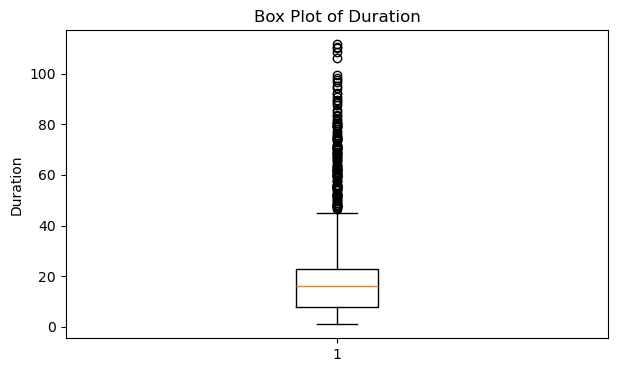

In [20]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Duration'].dropna())

plt.ylabel('Duration')
plt.title('Box Plot of Duration')

plt.show()

In [21]:
df['Duration'].describe()

count    15000.000000
mean        16.112574
std          9.833211
min          1.000000
25%          8.000000
50%         16.000000
75%         23.000000
max        111.609442
Name: Duration, dtype: float64

The box plot shows that the median workout duration is approximately 16 minutes, with the middle 50% of observations lying between 8 and 23 minutes. Values above approximately 45.5 minutes are identified as potential outliers using the IQR rule.

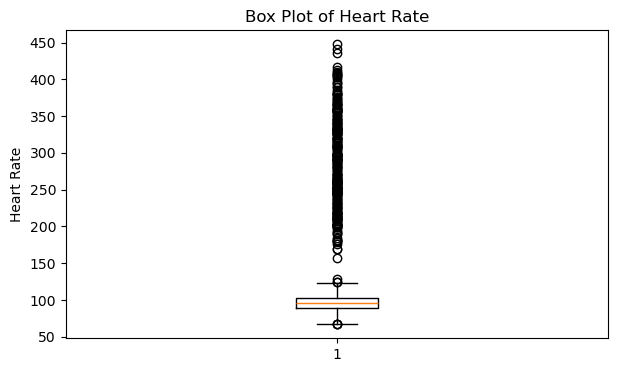

In [22]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Heart_Rate'].dropna())

plt.ylabel('Heart Rate')
plt.title('Box Plot of Heart Rate')

plt.show()

In [23]:
df['Heart_Rate'].describe()

count    14340.000000
mean        99.433386
std         29.929374
min         67.000000
25%         89.000000
50%         96.000000
75%        103.000000
max        447.635709
Name: Heart_Rate, dtype: float64

The box plot shows that the median heart rate is approximately 96 bpm, with the middle 50% of observations lying between 89 and 103 bpm. Values below approximately 68 bpm or above 124 bpm are identified as potential outliers using the IQR rule.

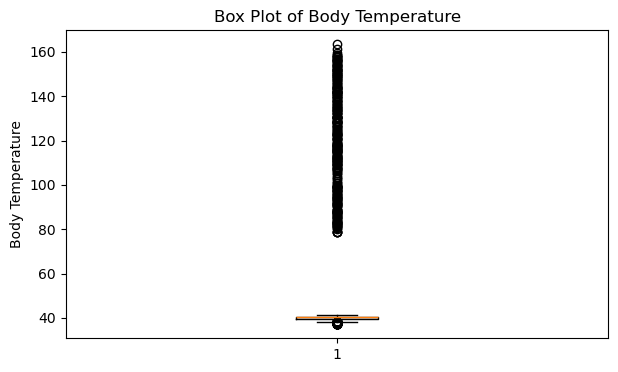

In [24]:
plt.figure(figsize=(7, 4))

plt.boxplot(df['Body_Temp'].dropna())

plt.ylabel('Body Temperature')
plt.title('Box Plot of Body Temperature')

plt.show()

In [25]:
df['Body_Temp'].describe()

count    15000.000000
mean        41.616467
std         11.645061
min         37.100000
25%         39.600000
50%         40.200000
75%         40.600000
max        163.437214
Name: Body_Temp, dtype: float64

The box plot shows that the median body temperature is approximately 40.2°C, with the middle 50% of observations lying between 39.6°C and 40.6°C. Values below approximately 38.1°C or above 42.1°C are identified as potential outliers using the IQR rule.

## Scatter Plot

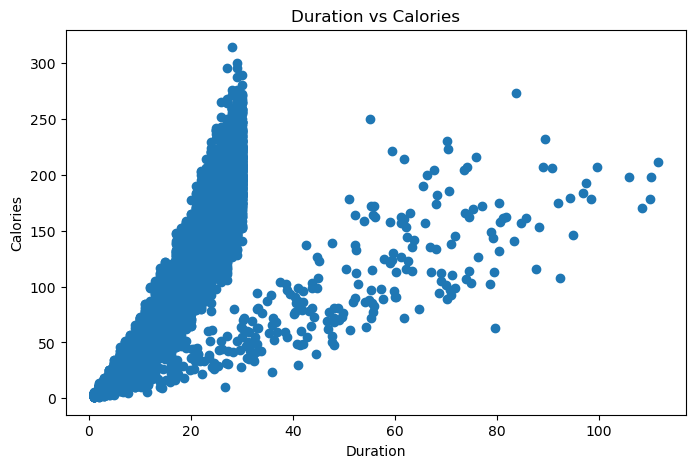

In [26]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Duration'], df['Calories'])

plt.xlabel('Duration')
plt.ylabel('Calories')
plt.title('Duration vs Calories')

plt.show()

The scatter plot shows a positive relationship between workout duration and calories burned, where calories generally increase as workout duration increases. However, the relationship is not perfectly linear, as the data points show some variation and several observations are relatively far from the general trend.

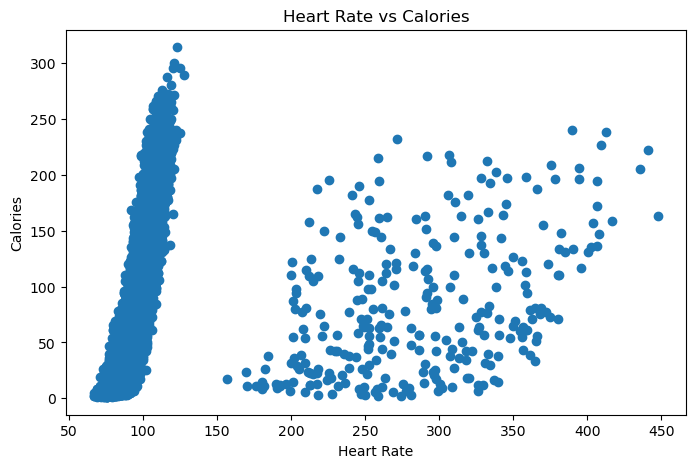

In [27]:
plt.figure(figsize=(8, 5))

plt.scatter(df['Heart_Rate'], df['Calories'])

plt.xlabel('Heart Rate')
plt.ylabel('Calories')
plt.title('Heart Rate vs Calories')

plt.show()

The scatter plot shows a generally positive relationship between heart rate and calories burned, with calories tending to increase as heart rate increases. However, the relationship is difficult to interpret clearly because of the extreme heart rate values and the considerable spread of observations.

## Correlation Heatmap

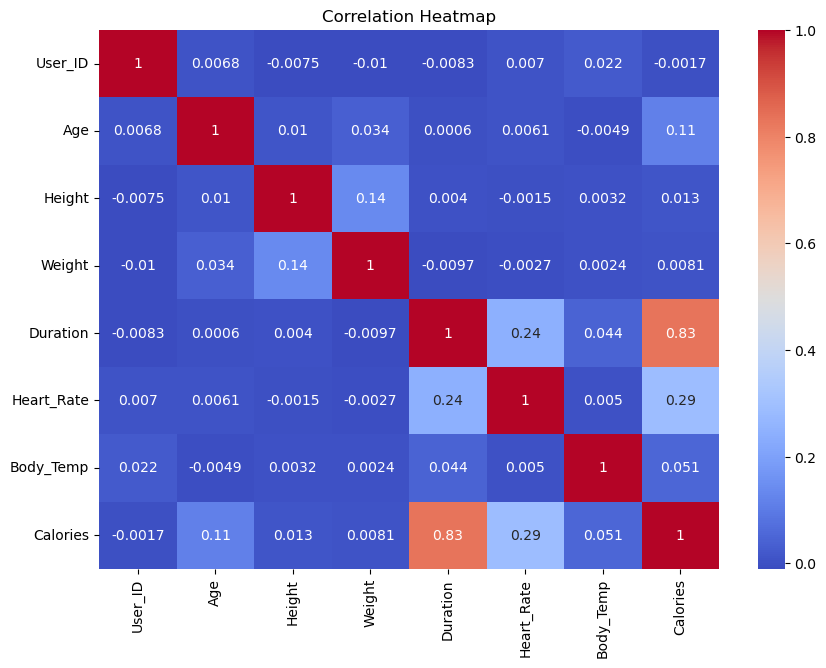

In [28]:
plt.figure(figsize=(10, 7))

correlation_matrix = df.corr(numeric_only=True)

sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

The correlation analysis shows that Duration has the strongest positive correlation with Calories (0.83), followed by Heart Rate (0.29). Age shows a weak positive correlation (0.11), while Body Temperature (0.051), Height (0.013), and Weight (0.0081) have very weak positive correlations with Calories.

# Data Cleaning
The dataset was cleaned by handling missing values, validating data types, and removing extreme invalid observations.

## Handling Missing Values

In [29]:
df.isnull().sum()

User_ID          0
Gender         900
Age              0
Height           0
Weight        1200
Duration         0
Heart_Rate     660
Body_Temp        0
Calories         0
dtype: int64

In [30]:
df['Gender'].mode()

0    female
Name: Gender, dtype: object

In [31]:
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])

In [32]:
df['Gender'].isnull().sum()

np.int64(0)

In [33]:
df['Weight'].median()

75.0

In [34]:
df['Weight'] = df['Weight'].fillna(df['Weight'].median())

In [35]:
df['Weight'].isnull().sum()

np.int64(0)

In [36]:
df['Heart_Rate'].median()

96.0

In [37]:
df['Heart_Rate'] = df['Heart_Rate'].fillna(df['Heart_Rate'].median())

In [38]:
df['Heart_Rate'].isnull().sum()

np.int64(0)

In [39]:
df.isnull().sum()

User_ID       0
Gender        0
Age           0
Height        0
Weight        0
Duration      0
Heart_Rate    0
Body_Temp     0
Calories      0
dtype: int64

In [40]:
df.dtypes

User_ID         int64
Gender         object
Age           float64
Height        float64
Weight        float64
Duration      float64
Heart_Rate    float64
Body_Temp     float64
Calories        int64
dtype: object

In [41]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -15.5
Upper Bound: 100.5


In [42]:
df[df['Age'] > upper_bound].shape[0]

173

In [43]:
df[df['Age'] > upper_bound]['Age'].describe()

count    173.000000
mean     168.164615
std       49.151084
min      100.864404
25%      127.876264
50%      160.495629
75%      194.404445
max      306.168733
Name: Age, dtype: float64

In [44]:
outlier_counts = {}

for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df[(df[feature] < lower_bound) | (df[feature] > upper_bound)]
    
    outlier_counts[feature] = len(outliers)

outlier_counts

{'Age': 173,
 'Height': 304,
 'Weight': 284,
 'Duration': 132,
 'Heart_Rate': 298,
 'Body_Temp': 661}

In [45]:
for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    print(feature)
    print("Min:", df[feature].min())
    print("Max:", df[feature].max())
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("-" * 20)

Age
Min: 20.0
Max: 306.1687327171889
Lower Bound: -15.5
Upper Bound: 100.5
--------------------
Height
Min: 123.0
Max: 802.138263909521
Lower Bound: 131.0
Upper Bound: 219.0
--------------------
Weight
Min: 36.0
Max: 438.0340457313351
Lower Bound: 31.0
Upper Bound: 119.0
--------------------
Duration
Min: 1.0
Max: 111.6094417133509
Lower Bound: -14.5
Upper Bound: 45.5
--------------------
Heart_Rate
Min: 67.0
Max: 447.635709068595
Lower Bound: 68.0
Upper Bound: 124.0
--------------------
Body_Temp
Min: 37.1
Max: 163.4372139643164
Lower Bound: 38.1
Upper Bound: 42.1
--------------------


In [46]:
df[df['Age'] > 100.5]['Age'].sort_values().head(20)

1806     100.864404
13310    101.299903
11071    102.130135
9441     103.390780
14640    103.436233
5985     103.997563
2688     104.875348
14110    106.074769
12013    106.809425
11129    107.825022
9149     107.864466
13161    109.413051
13723    109.925475
14107    110.085077
9937     110.328377
4028     110.411057
25       110.947146
5453     111.133565
826      111.832088
6125     112.016331
Name: Age, dtype: float64

In [47]:
for feature in numerical_features:
    Q1 = df[feature].quantile(0.25)
    Q3 = df[feature].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[feature] < lower_bound) |
        (df[feature] > upper_bound)
    ][feature]

    print("\nFeature:", feature)
    print("Number of potential outliers:", len(outliers))
    print("Minimum outlier:", outliers.min())
    print("Maximum outlier:", outliers.max())
    print("-" * 40)


Feature: Age
Number of potential outliers: 173
Minimum outlier: 100.8644035470411
Maximum outlier: 306.1687327171889
----------------------------------------

Feature: Height
Number of potential outliers: 304
Minimum outlier: 123.0
Maximum outlier: 802.138263909521
----------------------------------------

Feature: Weight
Number of potential outliers: 284
Minimum outlier: 119.5091745132198
Maximum outlier: 438.0340457313351
----------------------------------------

Feature: Duration
Number of potential outliers: 132
Minimum outlier: 46.6113632812513
Maximum outlier: 111.6094417133509
----------------------------------------

Feature: Heart_Rate
Number of potential outliers: 298
Minimum outlier: 67.0
Maximum outlier: 447.635709068595
----------------------------------------

Feature: Body_Temp
Number of potential outliers: 661
Minimum outlier: 37.1
Maximum outlier: 163.4372139643164
----------------------------------------


In [48]:
Q1 = df['Heart_Rate'].quantile(0.25)
Q3 = df['Heart_Rate'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['Heart_Rate'] < lower_bound) |
    (df['Heart_Rate'] > upper_bound)
]['Heart_Rate']

print("Number of potential outliers:", len(outliers))
print("Minimum outlier:", outliers.min())
print("Maximum outlier:", outliers.max())

Number of potential outliers: 298
Minimum outlier: 67.0
Maximum outlier: 447.635709068595


In [49]:
for feature in numerical_features:
    print("\n", feature)
    print(df[feature].sort_values(ascending=False).head(10).values)


 Age
[306.16873272 296.28175808 292.86669832 287.42491935 281.53082825
 279.02958155 276.17561646 265.78381866 265.24551281 264.50427405]

 Height
[802.13826391 744.58575976 735.41822222 730.79523513 726.80116472
 721.91460462 720.4102512  720.06593321 716.96807184 713.78659356]

 Weight
[438.03404573 413.17333898 406.14676928 384.88194429 373.31221459
 371.1842211  369.23685238 367.33569653 362.72557783 358.51733745]

 Duration
[111.60944171 110.34248015 110.10958758 108.61000286 106.04505757
  99.67055537  98.41885431  97.52090436  96.90539555  95.04636032]

 Heart_Rate
[447.63570907 441.12584221 435.91959078 416.9000898  412.90011433
 409.61948707 408.08450662 406.66423864 406.42169182 406.40074259]

 Body_Temp
[163.43721396 161.52555311 159.41884444 158.48216553 158.47959372
 158.34751239 157.78236322 157.7239702  157.55757674 156.96522231]


In [50]:
print("Rows before cleaning:", len(df))

Rows before cleaning: 15000


### Outlier Detection and Removal

In [51]:
df_clean = df[
    (df['Age'] <= 100) &
    (df['Height'] <= 250) &
    (df['Weight'] <= 250) &
    (df['Heart_Rate'] <= 220) &
    (df['Body_Temp'] <= 45)
].copy()

In [52]:
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))

Rows after cleaning: 13918
Rows removed: 1082


In [53]:
df_clean[numerical_features].describe()

,Age,Height,Weight,Duration,Heart_Rate,Body_Temp
count,13918.000000,13918.000000,13918.000000,13918.000000,13918.000000,13918.000000
mean,43.012535,174.414715,76.427133,16.135208,95.949427,40.027310
std,17.153773,14.208515,19.434999,9.867033,11.206594,0.779498
min,20.000000,123.000000,36.000000,1.000000,67.000000,37.100000
25%,28.000000,164.000000,64.000000,8.000000,89.000000,39.600000
50%,40.000000,174.000000,75.000000,16.000000,96.000000,40.200000
75%,56.000000,185.000000,86.000000,23.000000,103.000000,40.600000
max,98.228547,222.000000,248.261241,111.609442,219.244544,41.500000


##  Feature and Target Definition

In [54]:
features = [
    'Gender',
    'Age',
    'Height',
    'Weight',
    'Duration',
    'Heart_Rate',
    'Body_Temp'
]

X = df_clean[features]
y = df_clean['Calories']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (13918, 7)
y shape: (13918,)


In [55]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

categorical_features = ['Gender']

numerical_features = [
    'Age',
    'Height',
    'Weight',
    'Duration',
    'Heart_Rate',
    'Body_Temp'
]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

In [56]:
Z = preprocessor.fit_transform(X)

In [57]:
print("Encoded data shape:", Z.shape)

Encoded data shape: (13918, 8)


In [58]:
print(Z[:5])

[[ 1.45672694  1.09693698  0.90421911  1.30386247  0.80764041  0.99130173
   0.          1.        ]
 [-1.34159186 -0.59225171 -0.84526494 -0.21640597 -0.1739598   0.34984029
   1.          0.        ]
 [-0.52541554  0.3227255  -0.2792554  -0.3177572   0.3614585   0.60642487
   1.          0.        ]
 [-0.9335037  -1.43684605 -0.94817577 -0.62181088 -1.33403279 -0.29162115
   1.          0.        ]
 [-0.40881892 -1.64799463 -1.35981908  0.69575509  0.00451296  0.86300944
   1.          0.        ]]


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print(feature_names)

['num__Age' 'num__Height' 'num__Weight' 'num__Duration' 'num__Heart_Rate'
 'num__Body_Temp' 'cat__Gender_female' 'cat__Gender_male']


In [60]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(Z, y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [61]:
coefficients = linear_model.coef_

for feature, coefficient in zip(feature_names, coefficients):
    print(f"{feature}: {coefficient:.4f}")

num__Age: 8.5678
num__Height: 0.6341
num__Weight: 0.2669
num__Duration: 24.9772
num__Heart_Rate: 16.5565
num__Body_Temp: 21.6167
cat__Gender_female: -0.5421
cat__Gender_male: 0.5421


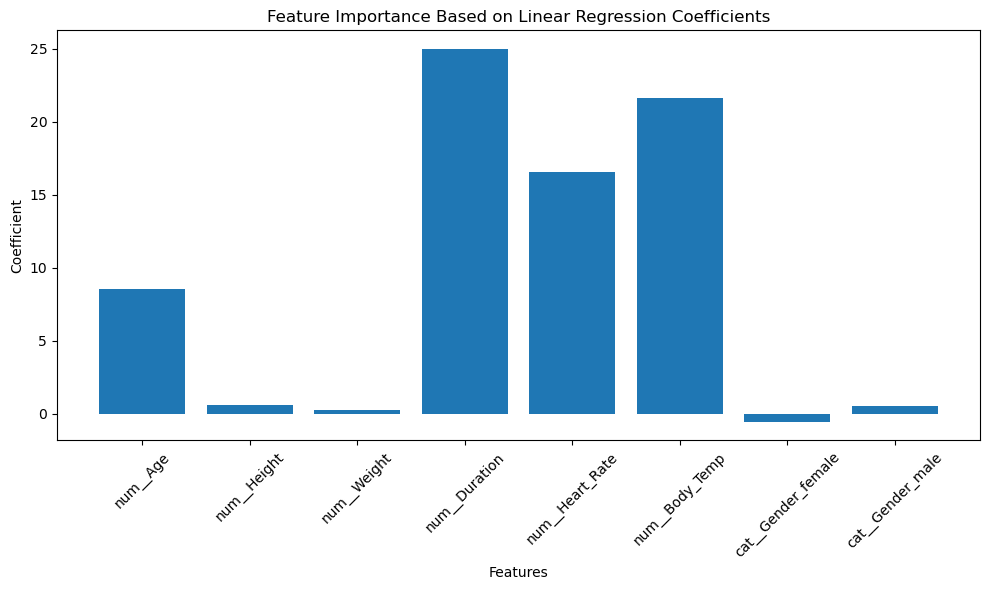

In [62]:
plt.figure(figsize=(10, 6))

plt.bar(feature_names, coefficients)

plt.xlabel('Features')
plt.ylabel('Coefficient')
plt.title('Feature Importance Based on Linear Regression Coefficients')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
from sklearn.linear_model import Lasso

lasso_model = Lasso(alpha=1.0)

lasso_model.fit(Z, y)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [64]:
lasso_coefficients = lasso_model.coef_

for feature, coefficient in zip(feature_names, lasso_coefficients):
    print(f"{feature}: {coefficient:.4f}")

num__Age: 7.5994
num__Height: 0.1705
num__Weight: 0.0000
num__Duration: 24.5453
num__Heart_Rate: 16.0299
num__Body_Temp: 21.2920
cat__Gender_female: -0.0000
cat__Gender_male: 0.0000


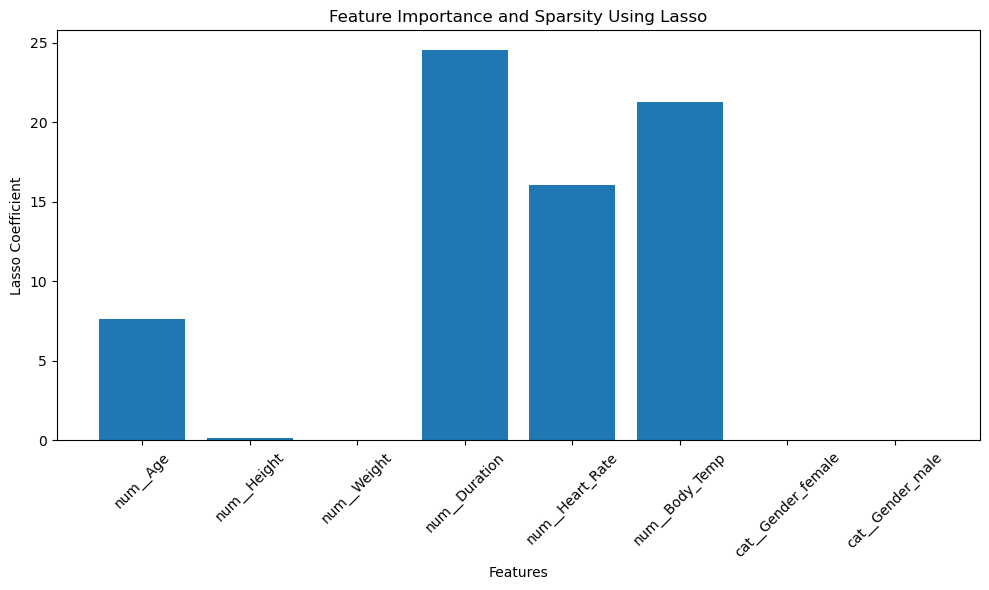

In [66]:
plt.figure(figsize=(10, 6))

plt.bar(feature_names, lasso_coefficients)

plt.xlabel('Features')
plt.ylabel('Lasso Coefficient')
plt.title('Feature Importance and Sparsity Using Lasso')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (11134, 7)
X_test shape: (2784, 7)
y_train shape: (11134,)
y_test shape: (2784,)


In [69]:
preprocessor_final = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        ), categorical_features)
    ]
)

In [70]:
Z_train = preprocessor_final.fit_transform(X_train)
Z_test = preprocessor_final.transform(X_test)

print("Z_train shape:", Z_train.shape)
print("Z_test shape:", Z_test.shape)

Z_train shape: (11134, 8)
Z_test shape: (2784, 8)


In [72]:
theta_normal = np.linalg.inv(
    Z_train.T @ Z_train
) @ Z_train.T @ y_train

In [74]:
y_pred_normal = Z_test @ theta_normal

In [75]:
from sklearn.metrics import r2_score

r2_normal = r2_score(y_test, y_pred_normal)

print("Normal Equation R²:", r2_normal)

Normal Equation R²: 0.8425714669936102


In [77]:
def gradient_descent(X, y, learning_rate=0.01, n_iterations=1000):
    m, n = X.shape
    
    theta = np.zeros(n)
    
    for _ in range(n_iterations):
        predictions = X @ theta
        
        gradients = (2 / m) * X.T @ (predictions - y)
        
        theta = theta - learning_rate * gradients
    
    return theta

In [79]:
theta_gd = gradient_descent(
    Z_train,
    y_train,
    learning_rate=0.01,
    n_iterations=1000
)

In [80]:
y_pred_gd = Z_test @ theta_gd

r2_gd = r2_score(y_test, y_pred_gd)

print("Gradient Descent R²:", r2_gd)

Gradient Descent R²: 0.8425825636778376


In [82]:
from sklearn.linear_model import Ridge

ridge_model = Ridge(alpha=1.0)

ridge_model.fit(Z_train, y_train)

,alpha,1.0
,fit_intercept,True
,copy_X,True
,max_iter,None
,tol,0.0001
,solver,'auto'
,positive,False
,random_state,None


In [83]:
y_pred_ridge = ridge_model.predict(Z_test)

r2_ridge = r2_score(y_test, y_pred_ridge)

print("Ridge R²:", r2_ridge)

Ridge R²: 0.842569139716896


In [85]:
lasso_decoder = Lasso(alpha=1.0)

lasso_decoder.fit(Z_train, y_train)

,alpha,1.0
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [86]:
y_pred_lasso = lasso_decoder.predict(Z_test)

r2_lasso = r2_score(y_test, y_pred_lasso)

print("Lasso R²:", r2_lasso)

Lasso R²: 0.8404878128482384


In [88]:
from sklearn.linear_model import ElasticNet

elastic_model = ElasticNet(
    alpha=1.0,
    l1_ratio=0.5
)

elastic_model.fit(Z_train, y_train)

,alpha,1.0
,l1_ratio,0.5
,fit_intercept,True
,precompute,False
,max_iter,1000
,copy_X,True
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [90]:
y_pred_elastic = elastic_model.predict(Z_test)

r2_elastic = r2_score(y_test, y_pred_elastic)

print("Elastic Net R²:", r2_elastic)

Elastic Net R²: 0.8026818125134135


In [92]:
results = pd.DataFrame({
    'Decoder': [
        'Normal Equation',
        'Gradient Descent',
        'Ridge',
        'Lasso',
        'Elastic Net'
    ],
    'R²': [
        r2_normal,
        r2_gd,
        r2_ridge,
        r2_lasso,
        r2_elastic
    ]
})

results = results.sort_values(by='R²', ascending=False)

results

,Decoder,R²
1,Gradient Descent,0.842583
0,Normal Equation,0.842571
2,Ridge,0.842569
3,Lasso,0.840488
4,Elastic Net,0.802682


### Best Decoder

Gradient Descent achieved the highest R² score of 0.84258, making it the best-performing decoder among the evaluated models.

However, the difference between Gradient Descent, Normal Equation, and Ridge is extremely small. This indicates that the three approaches provide nearly identical predictive performance on this dataset.

### Effect of Regularization

Regularization helps control model complexity and can reduce the risk of overfitting.

Ridge achieved an R² of 0.84257, which is almost identical to the unregularized models. This indicates that L2 regularization had little effect on predictive performance in this dataset.

Lasso achieved a slightly lower R² of 0.84049, but it produced sparse coefficients by reducing some feature coefficients to zero. This improves feature selection and interpretability.

Elastic Net achieved an R² of 0.80268 with the selected hyperparameters, which was lower than the other models. This indicates that this particular combination of L1 and L2 regularization was not optimal for this dataset.

### Effect of the Encoder

The encoder transformed the original mixed-type features into a numerical representation suitable for regression models.

Categorical data such as Gender was converted using One-Hot Encoding, while numerical features were standardized using Standard Scaling.

The final encoder was fitted only on the training data and then applied to the test data. This prevents data leakage and provides a more reliable evaluation of model generalization.

### Accuracy vs Interpretability

The results show a trade-off between predictive performance and interpretability.

Gradient Descent achieved the highest R², while Lasso provided a more sparse and interpretable model by setting some feature coefficients to zero.

Therefore, the best model depends on the objective. If predictive performance is the priority, Gradient Descent is preferred. If feature selection and interpretability are more important, Lasso can be useful despite its slightly lower R².

## Final Conclusion

This project developed an Encoder–Decoder regression pipeline for predicting Calories Burned from physiological and activity-related features.

The data was explored, cleaned, and preprocessed using appropriate techniques. Missing values were handled, extreme invalid observations were removed based on practical thresholds, categorical data was transformed using One-Hot Encoding, and numerical features were standardized using Standard Scaling.

Five different regression decoders were evaluated: Normal Equation, Gradient Descent, Ridge, Lasso, and Elastic Net. Gradient Descent achieved the highest R² score of **0.84258**, followed very closely by Normal Equation (**0.84257**) and Ridge (**0.84257**). Lasso achieved **0.84049**, while Elastic Net achieved **0.80268** with the selected hyperparameters.

Overall, the results show that the encoded features provide a strong representation for predicting calories burned, with **Duration** being one of the most influential features. Regularization had a limited effect on predictive performance for Ridge, while Lasso provided greater sparsity and feature selection at the cost of a small decrease in R².

The final evaluation also followed a proper train-test procedure, where the encoder was fitted only on the training data to avoid data leakage and provide a more reliable estimate of model generalization.

Therefore, **Gradient Descent was the best decoder based on R²**, while **Lasso offers a useful alternative when interpretability and feature sparsity are prioritized**.
